# Import a paired Run/Ch/Cy SPR export

Import **`paired_run.csv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it does not download data or fit a model.

**Data origin:** [rstoolbox example03/spr_data.txt](https://github.com/lpdi-epfl/rstoolbox/blob/2bfc9be5ec6111603fb78700f201b80331ef0132/notebook/data/example03/spr_data.txt). Copyright (c) 2017 Jaume Bonet, MIT license.
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/rstoolbox-LICENSE).

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd

# Works from the repository root, notebooks/ or docs/notebooks/.
repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "src" / "pykingenie").is_dir())
sys.path[:0] = [str(repo_root / "src"), str(repo_root / "notebooks")]

from pykingenie import KineticsAnalyzer, SprTextExperiment, detect_file_format
from pykingenie.utils.plotting import plot_association_dissociation, plot_traces_all
from notebook_helpers import show_plotly_static

data_folder = repo_root / "notebooks" / "data" / "spr_exports"
fit_metadata = json.loads((data_folder / "fit_metadata.json").read_text())

## File layout and representative selection

Paired `_X` time / `_Y` response columns. This teaching file contains the measured `conc=15`, `conc=30`, and `conc=60` series (cycles 14–16), with every finite source observation retained. There are 5,621 points per curve, rather than the 20-point weak-response curves in the separate parser-test fixture. No fitted curves are included.

The concentration labels have no verified unit and are not assumed to be µM. The source has 49 missing-response pairs in each selected curve. These 147 partial pairs are omitted from the teaching export; no finite response is discarded, and no value is interpolated or filled.

These exports do not establish injection-event timing. The boundaries below
remain **illustrative API partitions**, not verified experimental events.
Verify actual injection timing and concentrations before fitting. Boundaries
are seconds, and association is `[association_start, association_end)`.

The expected missing-concentration warning is displayed below.
`sample_id="unassigned"` is a grouping placeholder, not a recovered sample identity.

In [2]:
data_file = data_folder / "paired_run.csv"
print("Detected layout:", detect_file_format(data_file))

experiment = SprTextExperiment("paired_run")
experiment.read_file(
    data_file,
    association_start=0,    # illustrative; replace with the actual timing
    association_end=300,    # illustrative; replace with the actual timing
    decimal=".",
    sample_id="unassigned",
)

Detected layout: spr_text


/private/tmp/pykingenie-spr-input-parsers/src/pykingenie/utils/sensorgram_text.py:192: UserWarning: Some analyte concentrations are unavailable or have no unit. Provide concentrations or edit ligand_conc_df before fitting.
  warnings.warn(


## Imported curves and concentrations

Each measured curve becomes a sensor; its full exported label is kept as the
sensor name. `NaN` means the concentration is unknown, not zero. Supply verified
values with `concentrations=` and `concentration_unit=` before fitting.

In [3]:
experiment.ligand_conc_df

,Sensor,Analyte_location,Concentration_micromolar,SampleID,Replicate,Loading_location,Experiment
0,Run 1; Ch 1; Cy 14; RefSub; 1kx8_d02; conc=15,1,NaN,unassigned,1,0,paired_run
1,Run 1; Ch 1; Cy 15; RefSub; 1kx8_d02; conc=30,1,NaN,unassigned,1,0,paired_run
2,Run 1; Ch 1; Cy 16; RefSub; 1kx8_d02; conc=60,1,NaN,unassigned,1,0,paired_run


The three steps come from the boundaries passed to `read_file`, not from the signal.

In [4]:
experiment.df_steps

,#Step,Name,Type,Start,Column_location,Loading_location
0,1,Baseline,BASELINE,-36.900002,0,NaN
1,2,Association,ASSOC,0.000000,1,0
2,3,Dissociation,DISASSOC,300.000000,1,NaN


## Imported sensorgrams

All retained observations at their original times; no resampling, smoothing or baseline subtraction.

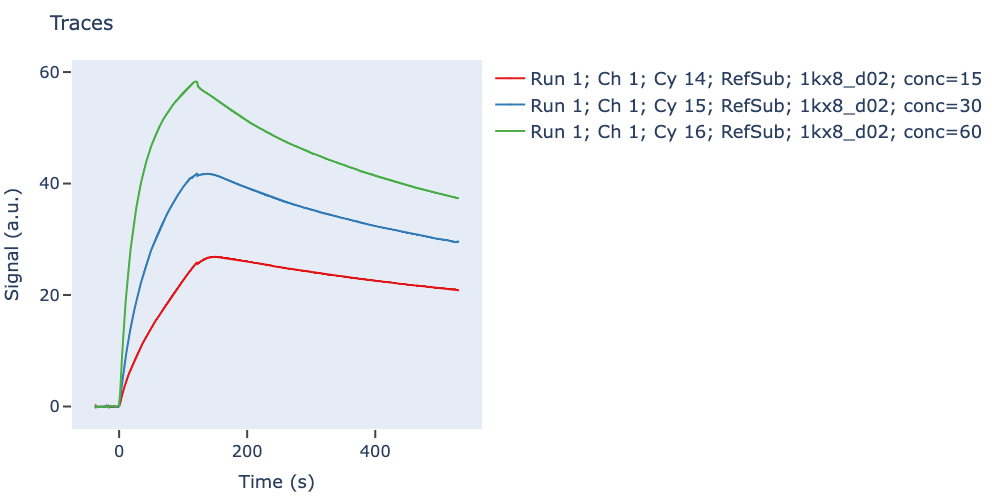

In [5]:
pyKinetics = KineticsAnalyzer()
pyKinetics.add_experiment(experiment, experiment.name)

show_plotly_static(plot_traces_all(pyKinetics, pyKinetics.get_legends_table()),
                   width=1000, height=500, scale=1)

These teaching exports contain complete source sampling for the selected
curves, excluding only the explicitly documented missing pairs. Their original
offsets and independent time grids are preserved. The small files used for parser
regression tests remain separate in `test_files/spr_exports/`.

Selection details, missing-pair counts, provenance and licenses:
[SOURCES.md](data/spr_exports/SOURCES.md).